# Cross-attention, foundation models and PEFT: the code behind the slides

AI 4200 · Deep learning. Each section reproduces the numbers on one or more slides. Everything runs on a CPU in seconds except the MNIST experiment, whose recorded results are loaded here (the full run is `vit_adaptation_comparison_marimo.py`, for a GPU on molab).

In [1]:
import json, math
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)

## 1. Cross-attention by hand
Slides: *Cross-attention*, *Every written word queries the source*. Queries from the decoder states Z, keys and values from the encoder output H.

In [2]:
"""Cross-attention by hand (slides: Cross-attention; Every written word queries every source word).

Source "the black cat sleeps" (encoder output H), target so far "<s> el gato" (decoder states Z).
Queries come from the decoder, keys and values from the encoder. Features and weights are illustrative.
No division by sqrt(d), as in the encoder lecture's running example.
"""
import json
import numpy as np

SOURCE = ["the", "black", "cat", "sleeps"]
TARGET = ["<s>", "el", "gato"]
NEXT = ["el", "gato", "negro"]
# encoder output: one row per source word, features (article, adjective, noun, verb)
H = np.eye(4)
# decoder state: one row per written word, features (start, article written, noun written)
Z = np.eye(3)
W_Q = 2.0 * np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0], [0, 0, 0]])   # start -> article, article -> noun, noun -> adjective
W_K = np.eye(4)
W_V = np.eye(4)


def softmax_rows(scores):
    exps = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return exps / exps.sum(axis=-1, keepdims=True)


def cross_attention(Z, H):
    """Queries from the decoder states Z, keys and values from the encoder output H."""
    Q = Z @ W_Q.T
    K = H @ W_K.T
    V = H @ W_V.T
    scores = Q @ K.T                    # t_target x t_source
    gates = softmax_rows(scores)
    return Q, K, scores, gates, gates @ V


Q, K, scores, gates, out = cross_attention(Z, H)
print("Q =\n", Q, "\nK =\n", K)
print("scores (target x source) =\n", scores)
print("gates =\n", gates.round(3))
print("output =\n", out.round(3))
print("gate matrix shape:", gates.shape, "(t_target x t_source)")
json.dump({"source": SOURCE, "target": TARGET, "next": NEXT, "Q": Q.tolist(), "K": K.tolist(),
           "scores": scores.tolist(), "gates": gates.round(3).tolist(), "out": out.round(3).tolist()},
          open("cross_attention.json", "w"), indent=1)

Q =
 [[2. 0. 0. 0.]
 [0. 0. 2. 0.]
 [0. 2. 0. 0.]] 
K =
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
scores (target x source) =
 [[2. 0. 0. 0.]
 [0. 0. 2. 0.]
 [0. 2. 0. 0.]]
gates =
 [[0.711 0.096 0.096 0.096]
 [0.096 0.096 0.711 0.096]
 [0.096 0.711 0.096 0.096]]
output =
 [[0.711 0.096 0.096 0.096]
 [0.096 0.096 0.711 0.096]
 [0.096 0.711 0.096 0.096]]
gate matrix shape: (3, 4) (t_target x t_source)


## 2. Four ways to adapt: weight counts for Llama 3 8B
Slide: *Four ways to adapt a foundation model*. Llama 3 8B: d = 4,096, 32 layers, grouped-query attention (the value projection maps 4,096 → 1,024).

In [3]:
d, layers, kv, r, classes, total = 4096, 32, 1024, 8, 2, 8_030_261_248
head = d * classes + classes
lora = layers * (r * (d + d) + r * (d + kv))   # query (4096 -> 4096) and value (4096 -> 1024)
print(f'In-context learning: 0\nNew head + frozen weights: {head:,}\nFull fine-tuning: {total / 1e9:.1f} B\nLoRA r = 8 on q and v: {lora / 1e6:.1f} M')

In-context learning: 0
New head + frozen weights: 8,194
Full fine-tuning: 8.0 B
LoRA r = 8 on q and v: 3.4 M


## 3. In-context learning, measured
Slide: *In-context learning, measured*. Numbers from Brown et al., 2020 (GPT-3), Table 3.3; T5 rows from Roberts et al., 2020. Not computed here, plotted for reference.

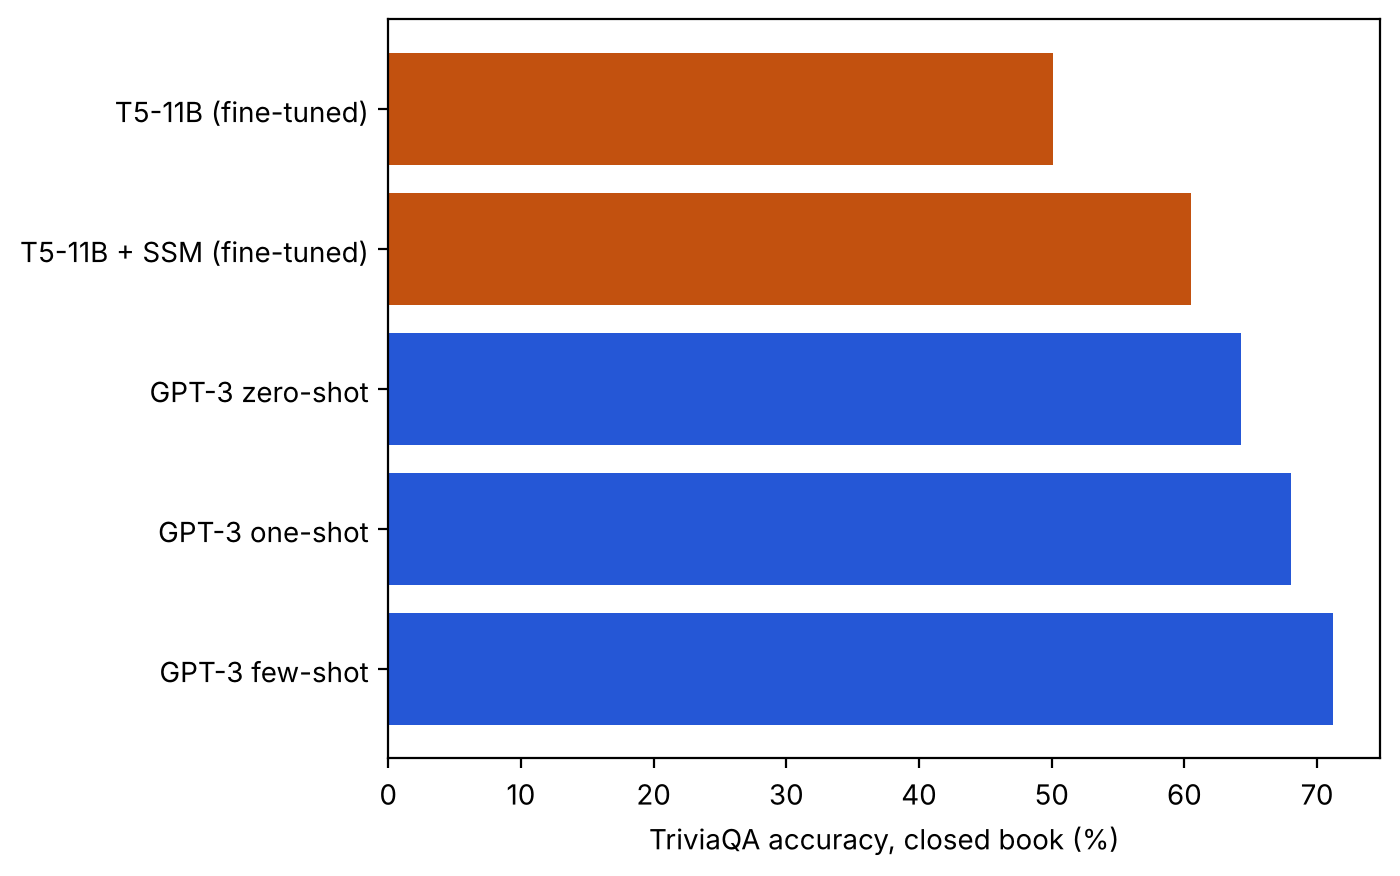

In [4]:
triviaqa = {'T5-11B (fine-tuned)': 50.1, 'T5-11B + SSM (fine-tuned)': 60.5, 'GPT-3 zero-shot': 64.3, 'GPT-3 one-shot': 68.0, 'GPT-3 few-shot': 71.2}
plt.barh(list(triviaqa), list(triviaqa.values()), color=['#C2510F'] * 2 + ['#2557D6'] * 3)
plt.gca().invert_yaxis(); plt.xlabel('TriviaQA accuracy, closed book (%)'); plt.show()

## 4. Head + frozen weights, LoRA + head, full fine-tuning on MNIST
Slides: *A new classifying head*, *Frozen weights*, *Three ways, measured*. ViT-B/16, mean of 3 seeds, 10,000 test images, recorded from the molab run of `vit_adaptation_comparison_marimo.py`.

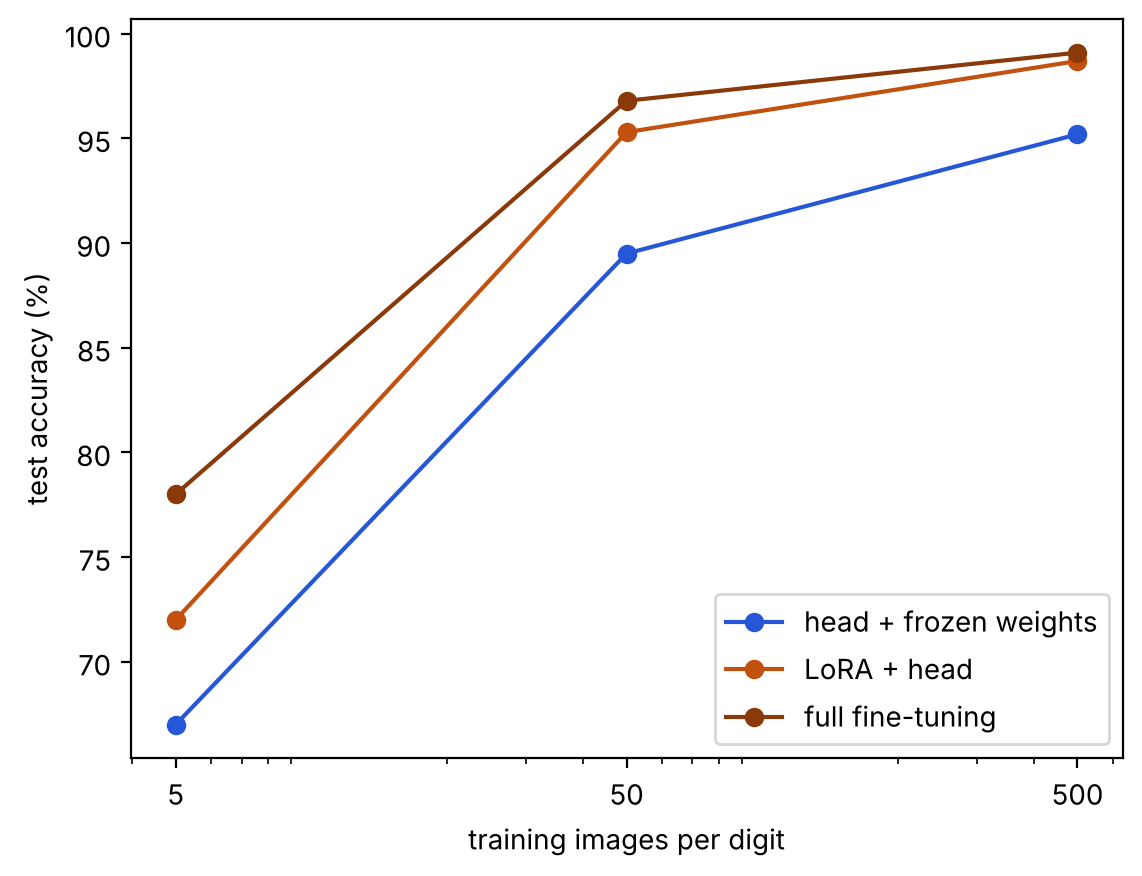

head + frozen weights  trained       7,690  file     0.03 MB  peak memory 0.4 GB
LoRA + head            trained     302,602  file     1.21 MB  peak memory 1.3 GB
full fine-tuning       trained  85,806,346  file   343.23 MB  peak memory 2.6 GB
full fine-tuning lead over LoRA: [6.0, 1.5, 0.4] points


In [5]:
per_digit = [5, 50, 500]
acc = {'head + frozen weights': [67.0, 89.5, 95.2], 'LoRA + head': [72.0, 95.3, 98.7], 'full fine-tuning': [78.0, 96.8, 99.1]}
trained = {'head + frozen weights': 768 * 10 + 10, 'LoRA + head': 302_602, 'full fine-tuning': 85_806_346}
memory_gb = {'head + frozen weights': 0.4, 'LoRA + head': 1.3, 'full fine-tuning': 2.6}
colours = {'head + frozen weights': '#2557D6', 'LoRA + head': '#C2510F', 'full fine-tuning': '#8A3A0A'}
for name, a in acc.items():
    plt.plot(per_digit, a, 'o-', color=colours[name], label=name)
plt.xscale('log'); plt.xticks(per_digit, per_digit); plt.xlabel('training images per digit'); plt.ylabel('test accuracy (%)'); plt.legend(); plt.show()
for name in acc:
    print(f'{name:22s} trained {trained[name]:>11,}  file {trained[name] * 4 / 1e6:8.2f} MB  peak memory {memory_gb[name]} GB')
print('full fine-tuning lead over LoRA:', [round(f - l, 1) for f, l in zip(acc['full fine-tuning'], acc['LoRA + head'])], 'points')

Gradients and Adam state for the *Frozen weights* table: 4 bytes per number, Adam keeps 2 numbers per trained weight.

In [6]:
for name in ('head + frozen weights', 'full fine-tuning'):
    n = trained[name]
    print(f'{name:22s} gradients {n * 4 / 1e6:8.2f} MB   Adam state {2 * n * 4 / 1e6:8.2f} MB')

head + frozen weights  gradients     0.03 MB   Adam state     0.06 MB
full fine-tuning       gradients   343.23 MB   Adam state   686.45 MB


## 5. LoRA by hand
Slide: *LoRA by hand*. One 4 × 4 layer, rank 1, α = 2.

In [7]:
"""LoRA on a 4 x 4 layer by hand (slides: LoRA by hand; Initialization).

Course notation: y_hat = x W^T. LoRA: y_hat = x W0^T + (alpha / r) x A^T B^T, W0 frozen, A (r x f) and B (n x r) trained.
The 'after training' B is illustrative; everything else follows from it.
"""
import json
import numpy as np

W0 = np.array([[1, 0, -1, 2], [0, 1, 1, 0], [2, -1, 0, 1], [1, 1, 0, -1]], dtype=float)
A = np.array([[1, 0, 1, 1]], dtype=float)            # r x f = 1 x 4
B_init = np.zeros((4, 1))                            # n x r, zero at the start
B_trained = np.array([[0.5], [0.0], [-1.0], [0.0]])  # illustrative
ALPHA, R = 2, 1
x = np.array([1, 2, 0, 1], dtype=float)
scale = ALPHA / R


def forward(x, B):
    frozen = x @ W0.T
    h = x @ A.T                       # r numbers
    update = scale * h @ B.T
    return frozen, h, update, frozen + update


out = {}
for name, B in [("init", B_init), ("trained", B_trained)]:
    frozen, h, update, y_hat = forward(x, B)
    out[name] = {"frozen": frozen.tolist(), "h": h.tolist(), "update": update.tolist(), "y_hat": y_hat.tolist(),
                 "BA": (B @ A).tolist(), "delta_W": (scale * B @ A).tolist()}
    print(name, "x W0^T =", frozen, " h = x A^T =", h, " update =", update, " y_hat =", y_hat)
W_merged = W0 + scale * B_trained @ A
assert np.allclose(x @ W_merged.T, out["trained"]["y_hat"])
print("merged W =\n", W_merged, "\nrank of delta W:", np.linalg.matrix_rank(B_trained @ A))

# gradients at the start, loss L = 0.5 * ||y_hat - target||^2 with the trained output as target
target = np.array(out["trained"]["y_hat"])
grads = {}
rng = np.random.default_rng(0)
for name, (A0, B0) in {"B = 0, A random": (A, B_init), "both zero": (np.zeros_like(A), B_init),
                       "both random": (A, rng.standard_normal((4, 1)).round(1))}.items():
    y_hat = x @ W0.T + scale * (x @ A0.T) @ B0.T
    dL_dy = y_hat - target
    dL_dB = scale * np.outer(dL_dy, x @ A0.T)        # n x r
    dL_dA = scale * np.outer(B0.T @ dL_dy, x)        # r x f
    grads[name] = {"delta_y": (y_hat - x @ W0.T).tolist(), "dL_dB": dL_dB.ravel().tolist(), "dL_dA": dL_dA.ravel().tolist(),
                   "B0": B0.ravel().tolist()}
    print(f"{name:16s} change in output at step 0: {y_hat - x @ W0.T}, dL/dB = {dL_dB.ravel()}, dL/dA = {dL_dA.ravel()}")
json.dump({"W0": W0.tolist(), "A": A.tolist(), "B_trained": B_trained.tolist(), "x": x.tolist(), "alpha": ALPHA, "r": R,
           "W_merged": W_merged.tolist(), "params_full": int(W0.size), "params_lora": int(A.size + B_init.size),
           **out, "grads": grads}, open("lora_by_hand.json", "w"), indent=1)

init x W0^T = [3. 2. 1. 2.]  h = x A^T = [2.]  update = [0. 0. 0. 0.]  y_hat = [3. 2. 1. 2.]
trained x W0^T = [3. 2. 1. 2.]  h = x A^T = [2.]  update = [ 2.  0. -4.  0.]  y_hat = [ 5.  2. -3.  2.]
merged W =
 [[ 2.  0.  0.  3.]
 [ 0.  1.  1.  0.]
 [ 0. -1. -2. -1.]
 [ 1.  1.  0. -1.]] 
rank of delta W: 1
B = 0, A random  change in output at step 0: [0. 0. 0. 0.], dL/dB = [-8.  0. 16.  0.], dL/dA = [0. 0. 0. 0.]
both zero        change in output at step 0: [0. 0. 0. 0.], dL/dB = [-0.  0.  0.  0.], dL/dA = [0. 0. 0. 0.]
both random      change in output at step 0: [ 0.4 -0.4  2.4  0.4], dL/dB = [-6.4 -1.6 25.6  1.6], dL/dA = [ 7.52 15.04  0.    7.52]


## 6. Rank 1, rank 2, rank 3 and the weight counts
Slides: *LoRA, starting at rank 1*, *What rank changes*.

In [8]:
"""Numbers for the 'LoRA, rank 1' and 'What rank changes' slides.
Weights trained for one n x f matrix, full update vs LoRA rank r; and the random rank-1 terms drawn as heatmaps."""
import json
import numpy as np

n = f = 768
counts = {"n": n, "f": f, "full": n * f, "lora": {r: r * (n + f) for r in (1, 8, 64)}}

rng = np.random.default_rng(3)
size = 8
b = np.round(rng.normal(size=(3, size)), 2)   # columns b1, b2, b3
a = np.round(rng.normal(size=(3, size)), 2)   # rows a1, a2, a3
terms = [np.outer(b[k], a[k]) for k in range(3)]
W0 = np.round(rng.normal(size=(size, size)), 2)  # a dense frozen matrix, for display
x = np.round(rng.normal(size=size), 2)
out = {"W0": W0.tolist(), "x": x.tolist(), "counts": counts, "b": b.tolist(), "a": a.tolist(),
       "terms": [t.round(3).tolist() for t in terms],
       "sum": sum(terms).round(3).tolist(),
       "rank_of_sum": [int(np.linalg.matrix_rank(sum(terms[:k + 1]))) for k in range(3)]}
json.dump(out, open("lora_rank.json", "w"), indent=1)
print(counts, out["rank_of_sum"])

{'n': 768, 'f': 768, 'full': 589824, 'lora': {1: 1536, 8: 12288, 64: 98304}} [1, 2, 3]


## 7. Initialization: B = 0, A random, three gradient steps
Slide: *Initialization: B = 0, A random*.

In [9]:
"""LoRA initialization slide: B = 0, A random. Three gradient steps on a toy 8 x 8 layer.
Records B, A, Delta W = B A and W = W0 + Delta W at steps 0..3, plus the loss."""
import json
import numpy as np

rng = np.random.default_rng(7)
n = f = 8
r = 2
W0 = rng.normal(size=(n, f))
u, v = rng.normal(size=n), rng.normal(size=f)
dW_true = np.outer(u, v) / 2                      # the change the task needs (rank 1)
X = rng.normal(size=(256, f))
Y = X @ (W0 + dW_true).T

A = rng.uniform(-1 / np.sqrt(f), 1 / np.sqrt(f), size=(r, f))   # LoRA default scale
B = np.zeros((n, r))
lr = 2.0
steps = []
for t in range(4):
    dW = B @ A
    err = X @ (W0 + dW).T - Y
    loss = float((err ** 2).mean())
    steps.append({"step": t, "B": B.round(4).tolist(), "A": A.round(4).tolist(), "dW": dW.round(4).tolist(),
                  "W": (W0 + dW).round(4).tolist(), "loss": round(loss, 3)})
    G = 2 * err.T @ X / err.size                  # dL/dW (n x f)
    gB, gA = G @ A.T, B.T @ G
    B, A = B - lr * gB, A - lr * gA
json.dump({"W0": W0.round(4).tolist(), "dW_true": dW_true.round(4).tolist(), "steps": steps}, open("lora_init_steps.json", "w"), indent=1)
for s in steps:
    print(s["step"], s["loss"], float(np.abs(np.array(s["dW"])).max()), float(np.abs(np.array(s["B"])).max()))

0 1.333 0.0 0.0
1 1.308 0.0457 0.1451
2 1.174 0.1392 0.2604
3 0.571 0.7037 0.6877


## 8. Two matrices: keep the variance
Slide: *Two matrices: keep the variance*. A check of var(A) = 1/f and var(B) = 1/r, plus the ÷r vs ÷√r scale.

In [10]:
"""Variance through the LoRA path (slide: Variance: A's init and the alpha / r scale).

Part 1: h = x A^T. With A ~ U(-1/sqrt(f), 1/sqrt(f)) (the init in the LoRA code: Kaiming uniform, a = sqrt(5)),
        var(h) = var(x) / 3 whatever the width f. With A ~ N(0, 1) it grows with f.
Part 2: update = s * h B^T is a sum of r terms. With random B as a stand-in for a trained one, its size grows
        like sqrt(r) for s = 1, shrinks like 1/sqrt(r) for s = 1/r (LoRA), and stays put for s = 1/sqrt(r) (rsLoRA).
"""
import json
import numpy as np

rng = np.random.default_rng(0)
N_X = 2000
rows_a = []
for f in [16, 64, 256, 768, 4096]:
    x = rng.standard_normal((N_X, f))
    bound = 1 / np.sqrt(f)
    A_kaiming = rng.uniform(-bound, bound, (8, f))
    A_unit = rng.standard_normal((8, f))
    rows_a.append({"f": f, "var_h_kaiming": float((x @ A_kaiming.T).var()), "var_h_unit": float((x @ A_unit.T).var())})
    print(f"f = {f:5d}: var(h) with the LoRA init {rows_a[-1]['var_h_kaiming']:.3f}, with N(0, 1) entries {rows_a[-1]['var_h_unit']:.0f}")

F = N = 768
x = rng.standard_normal((N_X, F))
rows_s = []
base = None
for r in [1, 4, 16, 64, 256]:
    bound = 1 / np.sqrt(F)
    A = rng.uniform(-bound, bound, (r, F))
    B = rng.standard_normal((N, r)) * 0.02          # stand-in for a trained B
    raw = (x @ A.T @ B.T).std()
    if base is None:
        base = raw
    rows_s.append({"r": r, "none": float(raw / base), "over_r": float(raw / r / base), "over_sqrt_r": float(raw / np.sqrt(r) / base)})
    print(f"r = {r:3d}: update size relative to r = 1: no scale {raw / base:5.2f}, / r {raw / r / base:.3f}, / sqrt(r) {raw / np.sqrt(r) / base:.2f}")
json.dump({"A_init": rows_a, "scale": rows_s}, open("lora_variance.json", "w"), indent=1)

f =    16: var(h) with the LoRA init 0.357, with N(0, 1) entries 17
f =    64: var(h) with the LoRA init 0.341, with N(0, 1) entries 66
f =   256: var(h) with the LoRA init 0.332, with N(0, 1) entries 262
f =   768: var(h) with the LoRA init 0.333, with N(0, 1) entries 732


f =  4096: var(h) with the LoRA init 0.335, with N(0, 1) entries 4087


r =   1: update size relative to r = 1: no scale  1.00, / r 1.000, / sqrt(r) 1.00
r =   4: update size relative to r = 1: no scale  2.03, / r 0.507, / sqrt(r) 1.01
r =  16: update size relative to r = 1: no scale  3.97, / r 0.248, / sqrt(r) 0.99
r =  64: update size relative to r = 1: no scale  8.01, / r 0.125, / sqrt(r) 1.00
r = 256: update size relative to r = 1: no scale 16.00, / r 0.063, / sqrt(r) 1.00


## 9. LoRA on ViT-B: the count
Slide: *LoRA on ViT-B: the count*.

In [11]:
"""Parameter counts for LoRA on ViT-B/16 (slide: LoRA on ViT-B: the count)."""
import json

D, BLOCKS, R = 768, 12, 8
TOTAL = 86_101_258                 # ViT-B/16 with a 10-class head plus the adapters, as printed by the workshop notebook
full_matrix = D * D
lora_matrix = R * (D + D)
adapted = 2 * BLOCKS               # query and value in every block
lora_total = adapted * lora_matrix
head = D * 10 + 10                 # the new 10-class head, weights and biases, trained
trainable = lora_total + head
out = {"full_matrix": full_matrix, "lora_matrix": lora_matrix, "ratio": lora_matrix / full_matrix, "adapted_matrices": adapted,
       "lora_total": lora_total, "head": head, "trainable": trainable, "total": TOTAL, "fraction": trainable / TOTAL}
print(out)
# GPT-3 175B, rank 4 on query and value (d = 12288, 96 blocks): our own count
gpt3 = 2 * 96 * 4 * (12288 + 12288)
out["gpt3_r4_qv"] = gpt3
print("GPT-3, r = 4 on q and v:", gpt3, "parameters;", gpt3 * 2 / 1e6, "MB at 2 bytes each")
json.dump(out, open("lora_count.json", "w"), indent=1)

{'full_matrix': 589824, 'lora_matrix': 12288, 'ratio': 0.020833333333333332, 'adapted_matrices': 24, 'lora_total': 294912, 'head': 7690, 'trainable': 302602, 'total': 86101258, 'fraction': 0.0035144898812047554}
GPT-3, r = 4 on q and v: 18874368 parameters; 37.748736 MB at 2 bytes each
